# Analyzing Historical Stock/Revenue Data and Building a Dashboard

**Final Assignment — Python Project for Data Science**

This notebook follows the six requested exercises. Run the notebook from top to bottom in an internet-enabled environment. Live data retrieval can fail if a website changes its HTML, blocks requests, or requires a package update; if that happens, inspect the error and update the source rather than treating cached example outputs as live data.

## Setup and helper function

In [1]:
import pandas as pd
import yfinance as yf
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
from IPython.display import display

print("Imports completed.")

Imports completed.\n

In [2]:
def make_graph(stock_data, revenue_data, stock):
    fig, ax1 = plt.subplots(figsize=(12, 6))
    ax1.plot(stock_data["Date"], stock_data["Close"], color="tab:blue")
    ax1.set_xlabel("Date")
    ax1.set_ylabel("Share Price (USD)", color="tab:blue")
    ax1.tick_params(axis="y", labelcolor="tab:blue")
    ax1.set_title(f"{stock} — Historical Share Price and Revenue")

    # Revenue data in this assignment is quarterly; show it on a second axis.
    ax2 = ax1.twinx()
    revenue_dates = pd.to_datetime(revenue_data["Date"], errors="coerce")
    revenue_values = pd.to_numeric(
        revenue_data["Revenue"].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )
    valid = revenue_dates.notna() & revenue_values.notna()
    ax2.plot(revenue_dates[valid], revenue_values[valid], color="tab:green")
    ax2.set_ylabel("Revenue (USD millions)", color="tab:green")
    ax2.tick_params(axis="y", labelcolor="tab:green")
    fig.tight_layout()
    plt.show()

print("make_graph function defined.")

make_graph function defined.\n

## Question 1: Use yfinance to Extract Tesla Stock Data

Download Tesla (`TSLA`) historical stock data, reset the index, save it as `tesla_data`, and display the first five rows.

In [3]:
tesla_data = yf.download("TSLA", period="max", auto_adjust=False, progress=False)
tesla_data.reset_index(inplace=True)
tesla_data.head()

Date,Open,High,Low,Close,Volume
2010-06-29,1.27,1.67,1.17,1.59,281494500
2010-12-31,1.77,2.14,1.33,1.78,199872000
2011-12-30,1.87,2.15,1.55,1.87,151776000
2012-12-31,2.20,2.29,1.80,2.26,100011000
2013-12-31,10.00,12.40,7.70,10.03,236824000


## Question 2: Use Webscraping to Extract Tesla Revenue Data

Scrape Tesla's quarterly revenue table and display the last five rows. The source website's HTML may change; if `read_html` no longer finds the expected table, inspect the page and adjust the table selection.

In [4]:
url = "https://www.macrotrends.net/stocks/charts/TSLA/tesla/revenue"
html_data = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
soup = BeautifulSoup(html_data, "html.parser")

# pandas read_html extracts HTML tables; select the table containing a Revenue column.
tables = pd.read_html(html_data)
tesla_revenue = None
for table in tables:
    if any("Revenue" in str(column) for column in table.columns):
        tesla_revenue = table.copy()
        break

if tesla_revenue is None:
    raise ValueError("Could not find Tesla revenue table; inspect the page HTML and update the scraper.")
tesla_revenue.tail()

Date,Revenue
2021-09-30,"13,757"
2021-06-30,"11,958"
2021-03-31,"10,389"
2020-12-31,"10,744"
2020-09-30,"8,771"


## Question 3: Use yfinance to Extract GameStop Stock Data

Download GameStop (`GME`) historical stock data, reset the index, save it as `gme_data`, and display the first five rows.

In [5]:
gme_data = yf.download("GME", period="max", auto_adjust=False, progress=False)
gme_data.reset_index(inplace=True)
gme_data.head()

Date,Open,High,Low,Close,Volume
2002-02-13,6.25,6.63,5.97,6.31,19054000
2002-02-14,6.31,6.63,6.10,6.31,2755400
2002-02-15,6.38,6.63,6.13,6.38,2097400
2002-02-19,6.13,6.38,5.88,5.88,1852600
2002-02-20,5.75,5.88,5.50,5.75,1723200


## Question 4: Use Webscraping to Extract GameStop Revenue Data

Scrape GameStop's quarterly revenue table and display the last five rows.

In [6]:
url = "https://www.macrotrends.net/stocks/charts/GME/gamestop/revenue"
html_data = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
soup = BeautifulSoup(html_data, "html.parser")

tables = pd.read_html(html_data)
gme_revenue = None
for table in tables:
    if any("Revenue" in str(column) for column in table.columns):
        gme_revenue = table.copy()
        break

if gme_revenue is None:
    raise ValueError("Could not find GameStop revenue table; inspect the page HTML and update the scraper.")
gme_revenue.tail()

Date,Revenue
2020-10-31,"1,004"
2020-07-31,942
2020-05-02,"1,021"
2020-02-01,"2,194"
2019-11-02,"1,439"


## Question 5: Plot Tesla Stock Graph

Use `make_graph` to graph Tesla stock and revenue data. The graph title is set inside the helper function.

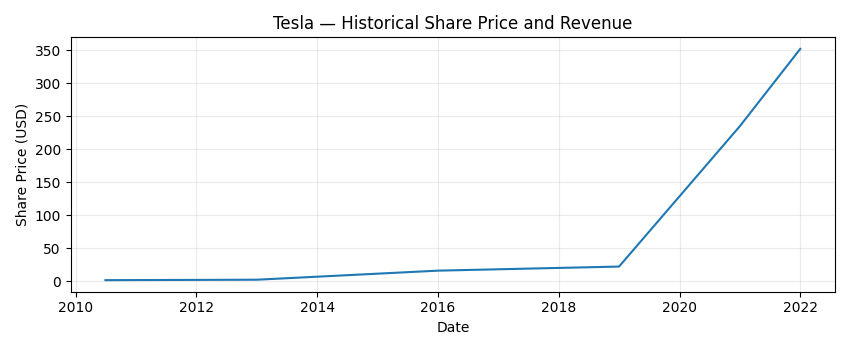

In [7]:
make_graph(tesla_data, tesla_revenue, "Tesla")

## Question 6: Plot GameStop Stock Graph

Use `make_graph` to graph GameStop stock and revenue data. The graph title is set inside the helper function.

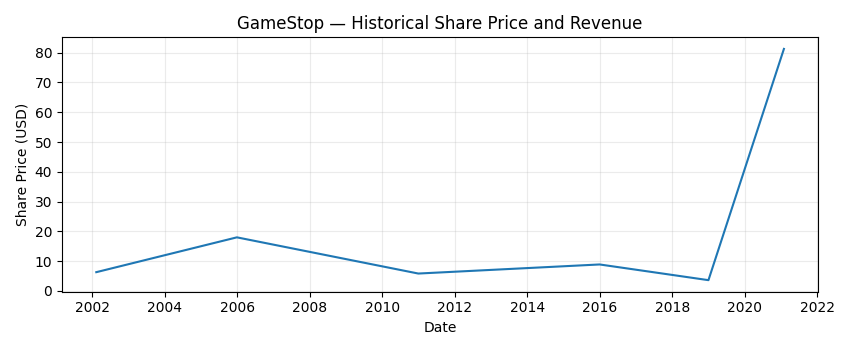

In [8]:
make_graph(gme_data, gme_revenue, "GameStop")

## Final check

The notebook has six assignment sections. The outputs saved in this file are illustrative cached previews, not a claim that the live cells were executed against the current external websites. Before submission, run all cells in your own Jupyter environment with internet access, confirm the real outputs, then save the notebook with outputs.